<a href="https://colab.research.google.com/github/irushoka-lang/ca-prison-commute-analysis/blob/main/California_Prison_Commute_Final_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Commuting distance of California state prison workers

**Question:** How far do people who work in California state prisons commute?

**Data**
- Prison boundaries (HIFLD) - where each prison is
- 2020 Census blocks (TIGER) - small geographic units
- LEHD LODES8 OD file - number of jobs for each home block -> work block pair
- LEHD LODES8 WAC file - jobs per workplace block (used only for checks and fixes)

**Steps**
1. Setup  2. Prison list  3. Prison -> census blocks  4. Load LODES  5. Fix block assignment
6. Build worker dataset  7. Commute distances  8. Results  9. Charts  10. Save

**Run order:** Runtime -> Restart session and run all.

In [115]:
# 1. SETUP ---------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

DATA_DIR  = '/content/drive/MyDrive/Python CS/Final/Datasets/'
LODES_DIR = f'{DATA_DIR}/LODES/OD'

YEAR     = 2022        # LODES8 for California covers 2002-2022
JOB_TYPE = 'JT00'      # JT00 = ALL jobs (includes state government). JT05 is federal only.
BASE_URL = 'https://lehd.ces.census.gov/data/lodes/LODES8/ca/od'

MIXED_CUTOFF = 0.7     # sites where <70% of block jobs are public administration are flagged

print(os.listdir(DATA_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['prison-boundaries-1-geojson.zip', 'california_state_prisons_surveys.csv', 'Prison_boundaries.geojsong', 'tlgdb_2020_a_06_ca.gdb', 'tl_2010_06_tabblock10', 'ca_xwalk.csv', 'prison_blocks_2020.csv', 'LODES', 'prison_commute_results.csv', 'prison_workers_lodes.csv']


## 2. Prison list

In [116]:
detention_facilities = gpd.read_file(f'{DATA_DIR}/prison-boundaries-1-geojson.zip')

detention_facilities = detention_facilities.drop(columns=[
    'TELEPHONE', 'OBJECTID', 'ADDRESS', 'SOURCE', 'VAL_METHOD',
    'Shape__Area', 'Shape__Length', 'SECURELVL'], errors='ignore')

detention_facilities.columns = detention_facilities.columns.str.lower()
detention_facilities = detention_facilities[detention_facilities['type'] == 'STATE']
california = detention_facilities[detention_facilities['state'] == 'CA'].copy()

# CDCR institutions whose names do not contain "STATE PRISON"
keep_exact = [
    'CALIFORNIA MEDICAL FACILITY (CMF)', 'CALIFORNIA HEALTH CARE FACILITY (CHCF)',
    'SIERRA CONSERVATION CENTER (SCC)', 'CORRECTIONAL TRAINING FACILITY (CTF)',
    "CALIFORNIA MEN'S COLONY (CMC)", 'CALIFORNIA CORRECTIONAL INSTITUTION (CCI)',
    'CALIFORNIA INSTITUTION FOR MEN (CIM)', 'CALIFORNIA INSTITUTION FOR WOMEN (CIW)',
    'CALIFORNIA REHABILITATION CENTER (CRC)', 'R J DONOVAN CORRECTIONAL FACILITY (RJD)',
    "CENTRAL CALIFORNIA WOMEN'S FACILITY (CCFW)"]

mask = california['name'].str.contains('STATE PRISON') | california['name'].isin(keep_exact)
california_prisons = california[mask].copy()

# lowercase names and make "prison(pvsp)" -> "prison (pvsp)"
california_prisons['name'] = (california_prisons['name'].str.lower().str.strip()
                              .str.replace(r'\s*\(', ' (', regex=True))

print(len(california_prisons), 'prisons selected')

# CHECK: California state facilities NOT selected - add any real CDCR prison you see here
california['name'] = california['name'].str.lower()
not_selected = california.loc[~california.index.isin(california_prisons.index), 'name'].sort_values()
print('\nNot selected:'); print(not_selected.to_string())

31 prisons selected

Not selected:
5961                      acton conservation camp #11
1517                      alder conservation camp #20
2353                   antelope conservation camp #25
5142            baker community correctional facility
5129                   baseline conservation camp #30
5097                   bautista conservation camp #36
2653                 ben lomond conservation camp #45
5021     ca substance abuse treatment facility (satf)
5012        california city correctional center (cac)
5940             california correctional center (ccc)
5943                             central valley annex
5380          chamberlain creek conservation camp #17
5156                         claremont custody center
5126                     cuesta conservation camp #24
5107                   deadwood conservation camp #23
5952                       delta conservation camp #8
5996       department of state hospitals - atascadero
6001         department of state hospitals - co

In [117]:
# Establishment years (for an optional look at prison age vs commute)
establishment_years = {
    "calipatria state prison (cal)": 1992, "centinela state prison (cen)": 1993,
    "california state prison, solano (sol)": 1984, "avenal state prison": 1987,
    "california men's colony (cmc)": 1954, "california state prison, corcoran (cor)": 1988,
    "central california women's facility (ccfw)": 1990, "chuckawalla valley state prison (cvsp)": 2003,
    "r j donovan correctional facility (rjd)": 1987, "pelican bay state prison (pbsp)": 1989,
    "pleasant valley state prison (pvsp)": 1994, "valley state prison (vsp)": 1995,
    "high desert state prison (hdsp)": 1995, "california health care facility (chcf)": 2013,
    "folsom state prison (fsp)": 1880, "mule creek state prison (mcsp)": 1987,
    "california correctional institution (cci)": 1954, "california institution for men (cim)": 1941,
    "correctional training facility (ctf)": 1946, "california institution for women (ciw)": 1952,
    "california medical facility (cmf)": 1955, "california rehabilitation center (crc)": 1962,
    "california state prison, sacramento (sac)": 1986, "california state prison-los angeles county (lac)": 1993,
    "san quentin state prison (sq)": 1852, "wasco state prison (wsp)": 1991,
    "north kern state prison (nksp)": 1993, "sierra conservation center (scc)": 1965,
    "kern valley state prison (kvsp)": 2005, "ironwood state prison (isp)": 1994,
    "salinas valley state prison (svsp)": 1996}

california_prisons['establishment_year'] = california_prisons['name'].map(establishment_years)
print('Prisons with no establishment year (should be empty):',
      list(california_prisons.loc[california_prisons['establishment_year'].isna(), 'name']))

Prisons with no establishment year (should be empty): []


## 3. Prison -> census blocks

In [118]:
gdb_path = f'{DATA_DIR}/tlgdb_2020_a_06_ca.gdb'
block_2020 = gpd.read_file(gdb_path, layer='Block20')

if 'GEOID20' in block_2020.columns and 'GEOID' not in block_2020.columns:
    block_2020 = block_2020.rename(columns={'GEOID20': 'GEOID'})
block_2020['GEOID'] = block_2020['GEOID'].astype(str).str.zfill(15)
block_2020 = block_2020[['GEOID', 'geometry']]

# same coordinate system as the prisons, then every block touching a prison polygon
block_2020 = block_2020.to_crs(california_prisons.crs)
prison_blocks_joined = gpd.sjoin(
    block_2020, california_prisons[['name', 'geometry']],
    how='inner', predicate='intersects')[['name', 'GEOID', 'geometry']]

print(prison_blocks_joined['name'].nunique(), 'prisons,', len(prison_blocks_joined), 'blocks')

31 prisons, 51 blocks


## 4. Load LODES (jobs by home block and work block)

In [119]:
def get_lodes_od(year, job_type='JT00', parts=('main', 'aux')):
    """main = lives AND works in CA; aux = works in CA but lives out of state. Both are needed."""
    frames = []
    for part in parts:
        fname = f'ca_od_{part}_{job_type}_{year}.csv.gz'
        local = os.path.join(LODES_DIR, fname)
        path = local if os.path.exists(local) else f'{BASE_URL}/{fname}'   # download if not on Drive
        df = pd.read_csv(path, dtype={'w_geocode': str, 'h_geocode': str})
        df['lodes_part'] = part
        frames.append(df)
        print(f"{fname}: {df['S000'].sum():,} jobs ({'drive' if path == local else 'LEHD download'})")
    od = pd.concat(frames, ignore_index=True)
    od['w_geocode'] = od['w_geocode'].str.zfill(15)
    od['h_geocode'] = od['h_geocode'].str.zfill(15)
    return od

od = get_lodes_od(YEAR, JOB_TYPE)

# WAC = jobs per workplace block. Used only for the fixes and checks below.
wac = pd.read_csv(f"{BASE_URL.replace('/od', '/wac')}/ca_wac_S000_{JOB_TYPE}_{YEAR}.csv.gz",
                  dtype={'w_geocode': str})
wac['w_geocode'] = wac['w_geocode'].str.zfill(15)
print(f"OD total {od['S000'].sum():,}  vs  WAC total {wac['C000'].sum():,}  (should be within ~1-2%)")

od

ca_od_main_JT00_2022.csv.gz: 17,430,636 jobs (LEHD download)
ca_od_aux_JT00_2022.csv.gz: 223,254 jobs (LEHD download)
OD total 17,653,890  vs  WAC total 17,653,890  (should be within ~1-2%)


,w_geocode,h_geocode,S000,SA01,SA02,SA03,SE01,SE02,SE03,SI01,SI02,SI03,createdate,lodes_part
0,060014001001003,060014048002006,1,0,0,1,0,0,1,0,0,1,20240920,main
1,060014001001003,060014054021007,1,0,1,0,0,0,1,0,0,1,20240920,main
2,060014001001003,060014206001009,1,0,0,1,0,0,1,0,0,1,20240920,main
3,060014001001003,060014206002003,1,0,0,1,0,0,1,0,0,1,20240920,main
4,060014001001003,060014206002007,1,0,1,0,1,0,0,0,0,1,20240920,main
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16305078,061150411013005,320030005141000,1,1,0,0,0,1,0,0,1,0,20240920,aux
16305079,061150411013005,320310022083003,1,0,1,0,0,0,1,0,1,0,20240920,aux
16305080,061150411021018,320310022132010,1,0,0,1,1,0,0,0,0,1,20240920,aux
16305081,061150411021037,320310035123003,1,0,1,0,1,0,0,1,0,0,20240920,aux


## 5. Fix which blocks belong to which prison

Three known problems:
1. For five prisons the HIFLD polygon misses the block where LODES places the jobs. Nearby government-heavy blocks are added (CMF's block is health care, so it is added by hand).
2. Folsom and New Folsom (Sacramento) share a block. LODES cannot separate them, so they become one site.
3. Some blocks also hold other employers (e.g. a hospital next to Pleasant Valley). Those sites are flagged, not changed.

In [120]:
mapping = prison_blocks_joined[['GEOID', 'name']].drop_duplicates().copy()

# (1) add nearby blocks for prisons whose polygon missed the jobs
low = ['california medical facility (cmf)', "california men's colony (cmc)",
       'san quentin state prison (sq)', 'correctional training facility (ctf)',
       'centinela state prison (cen)']

cand = block_2020.merge(wac[['w_geocode', 'C000', 'CNS20']], left_on='GEOID', right_on='w_geocode')
cand = cand[(cand['C000'] > 0) & (cand['CNS20'] / cand['C000'] >= 0.8)]   # mostly government jobs
cand = cand[~cand['GEOID'].isin(mapping['GEOID'])]                         # not already assigned

cand_p = gpd.GeoDataFrame(cand, geometry='geometry', crs=block_2020.crs).to_crs(5070)
prisons_p = california_prisons[['name', 'geometry']].to_crs(5070)
near = gpd.sjoin_nearest(cand_p, prisons_p, how='inner', max_distance=1000, distance_col='dist_m')
near = near.sort_values('dist_m').drop_duplicates('GEOID')
near = near[near['name'].isin(low)]
print('Blocks added by the nearby-block fix:'); print(near.groupby('name')[['C000', 'CNS20']].sum())
mapping = pd.concat([mapping, near[['GEOID', 'name']]]).drop_duplicates()

# CMF: the block next to the prison (63 m away) is 99% health care jobs (2,214 of 2,227), so the
# 80%-public-administration rule above rejected it. Assigned by hand; it is flagged as a mixed site below.
cmf_block = pd.DataFrame({'GEOID': ['060952530001001'], 'name': ['california medical facility (cmf)']})
mapping = pd.concat([mapping, cmf_block]).drop_duplicates()

# (2) Folsom + New Folsom share a block -> one site
pair = ['folsom state prison (fsp)', 'california state prison, sacramento (sac)']
mapping.loc[mapping['name'].isin(pair), 'name'] = 'folsom + sacramento (combined)'
mapping = mapping.drop_duplicates()
print('\nBlocks assigned to more than one prison (should be 0):',
      int(mapping.groupby('GEOID')['name'].nunique().gt(1).sum()))

# (3) flag sites that share their block with other employers
chk = (wac.merge(mapping, left_on='w_geocode', right_on='GEOID')
          .groupby('name')[['C000', 'CNS20']].sum())
chk['pa_share'] = chk['CNS20'] / chk['C000']
mixed_sites = set(chk.index[chk['pa_share'] < MIXED_CUTOFF])
print('Mixed sites (flagged):', sorted(mixed_sites))

Blocks added by the nearby-block fix:
                               C000  CNS20
name                                      
california men's colony (cmc)   448    413
centinela state prison (cen)   1021    997
san quentin state prison (sq)  1825   1822

Blocks assigned to more than one prison (should be 0): 0
Mixed sites (flagged): ['avenal state prison', 'california medical facility (cmf)', 'california state prison, corcoran (cor)', 'chuckawalla valley state prison (cvsp)']


## 6. Worker dataset (one row = jobs from one home block to one prison)

In [121]:
prison_workers = od.merge(mapping, left_on='w_geocode', right_on='GEOID', how='inner')
prison_workers = prison_workers.rename(columns={'name': 'prison'})
prison_workers['same_block'] = prison_workers['h_geocode'] == prison_workers['w_geocode']  # live where they work
prison_workers['mixed_site'] = prison_workers['prison'].isin(mixed_sites)
prison_workers = prison_workers[['prison', 'w_geocode', 'h_geocode', 'S000', 'SA01', 'SA02', 'SA03','SE01', 'SE02', 'SE03','SI01', 'SI02', 'SI03',
                                 'same_block', 'mixed_site', 'lodes_part']]

by_prison = prison_workers.groupby('prison')['S000'].sum().sort_values(ascending=False)
print(f"Total prison jobs: {by_prison.sum():,} across {by_prison.size} sites")
print(by_prison.to_string())
print('\nPrisons with no jobs:',
      sorted(set(california_prisons['name']) - set(pair) - set(by_prison.index)))




Total prison jobs: 45,739 across 30 sites
prison
california state prison, corcoran (cor)             3697
folsom + sacramento (combined)                      2657
avenal state prison                                 2408
california medical facility (cmf)                   2227
california institution for men (cim)                2145
california health care facility (chcf)              2139
r j donovan correctional facility (rjd)             2039
mule creek state prison (mcsp)                      2009
california state prison-los angeles county (lac)    1853
san quentin state prison (sq)                       1841
california correctional institution (cci)           1669
wasco state prison (wsp)                            1662
north kern state prison (nksp)                      1519
salinas valley state prison (svsp)                  1450
california state prison, solano (sol)               1426
central california women's facility (ccfw)          1335
calipatria state prison (cal)          

## 7. Commuting distance

Distance = straight line from the **centre of the home block** to the **centre of the work block**, in miles
(California Albers projection, EPSG:3310). Workers who live outside California are not in the California block
file, so they have no distance. They are counted and reported but left out of the averages.

In [122]:
import geopandas as gpd
import pandas as pd
# Convert blocks to metres and find their centre points
blocks_albers = block_2020.to_crs(3310)
cent = blocks_albers.geometry.centroid

# Match each GEOID to its centroid
xy = pd.Series(cent.values, index=blocks_albers["GEOID"])

# Get home and work centroids
home = gpd.GeoSeries(prison_workers["h_geocode"].map(xy))
work = gpd.GeoSeries(prison_workers["w_geocode"].map(xy))

# Calculate Euclidean distance and convert metres to miles
prison_workers["miles"] = home.distance(work) * 0.000621371

# Keep observations with a valid distance
pw_d = prison_workers.dropna(subset=["miles"])


## 8. Results

In [148]:
#Adding demographic data
# Weighted median function
def wmedian(values, weights):
    order = np.argsort(values.values)
    v, w = values.values[order], weights.values[order]
    cw = np.cumsum(w)
    return v[np.searchsorted(cw, cw[-1] / 2)]


# Calculate distance statistics for each prison
def summarise(d):
    w = d['S000']

    return pd.Series({
        'jobs_with_distance': w.sum(),
        'mean_miles': np.average(d['miles'], weights=w),
        'median_miles': wmedian(d['miles'], w),
        'share_within_10mi': w[d['miles'] <= 10].sum() / w.sum(),
        'share_over_50mi': w[d['miles'] > 50].sum() / w.sum(),
        'share_same_block': w[d['same_block']].sum() / w.sum(),
    })


# Create one row per prison with distance statistics
results = pw_d.groupby('prison').apply(summarise)


# Add total jobs per prison
results['total_jobs'] = prison_workers.groupby('prison')['S000'].sum()


# Add mixed-site indicator
results['mixed_site'] = results.index.isin(mixed_sites)


# Add establishment year
results['establishment_year'] = [
    establishment_years.get(p) if p in establishment_years else
    (min(establishment_years[x] for x in pair)
     if p.startswith('folsom +') else np.nan)
    for p in results.index
]


# Add demographic and industry job counts per prison
demographic_cols = [
    'SA01', 'SA02', 'SA03',    # Age
    'SE01', 'SE02', 'SE03',    # Earnings
    'SI01', 'SI02', 'SI03'     # Industry
]

for col in demographic_cols:
    results[col] = pw_d.groupby('prison')[col].sum()


# Rename demographic columns to make them easier to understand
results = results.rename(columns={
    'SA01': 'age_29_or_younger',
    'SA02': 'age_30_to_54',
    'SA03': 'age_55_or_older',

    'SE01': 'earnings_1250_or_less',
    'SE02': 'earnings_1251_to_3333',
    'SE03': 'earnings_over_3333',

    'SI01': 'goods_producing industry',
    'SI02': 'trade_transport_utilities industry',
    'SI03': 'Services industry'
})


# Sort by average commuting distance
results = results.sort_values('mean_miles').round(3)
results

/tmp/ipykernel_2452/1400279767.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  results = pw_d.groupby('prison').apply(summarise)


,jobs_with_distance,mean_miles,median_miles,share_within_10mi,share_over_50mi,share_same_block,total_jobs,mixed_site,establishment_year,age_29_or_younger,age_30_to_54,age_55_or_older,earnings_1250_or_less,earnings_1251_to_3333,earnings_over_3333,goods_producing industry,trade_transport_utilities industry,Services industry
prison,,,,,,,,,,,,,,,,,,
folsom + sacramento (combined),2651.0,17.658,12.273,0.378,0.041,0.003,2657,False,1880,194,1871,586,55,96,2500,0,5,2646
correctional training facility (ctf),4.0,19.594,19.300,0.000,0.000,0.000,4,False,1946,0,3,1,0,0,4,0,0,4
california rehabilitation center (crc),789.0,19.876,12.640,0.431,0.041,0.000,790,False,1962,52,545,192,15,23,751,0,0,789
california institution for women (ciw),986.0,20.307,16.294,0.304,0.029,0.002,988,False,1952,58,728,200,26,38,922,0,0,986
centinela state prison (cen),1034.0,21.381,13.286,0.013,0.088,0.001,1071,False,1993,75,758,201,25,27,982,0,0,1034
california institution for men (cim),2144.0,21.886,16.784,0.267,0.034,0.000,2145,False,1941,105,1549,490,25,46,2073,0,0,2144
california medical facility (cmf),2221.0,23.282,20.271,0.381,0.066,0.000,2227,False,1955,134,1638,449,223,104,1894,0,0,2221
california health care facility (chcf),2134.0,25.068,16.774,0.290,0.119,0.000,2139,False,2013,120,1505,509,86,154,1894,0,0,2134
california correctional institution (cci),1669.0,26.871,27.836,0.419,0.101,0.000,1669,False,1954,113,1242,314,38,45,1586,0,0,1669


#9. Exploratory Data Analysis

#Descriptive statistics

In [124]:
# Units of Observations (Number of prisons):
print(f" There are {len(results)} units of observation in our data, and our uits of observations are california prisons by distinct blocks ")

#number of variables:
print(f"There {results.shape[1]} variables of interest in our dataset")

#Number of prisons with Mixed_sites:
mixed_sites = results[results["mixed_site"] == True]
print(f"There are {len(mixed_sites)} sites who are considered mixed sites meaning, 70% jobs in the block are not related to the prison, un-prison employment categories.")


#Number of missing data
Total_n_jobs = results["total_jobs"].sum()
Total_jobs_distance = results["jobs_with_distance"].sum()
print(f"There are {Total_n_jobs - Total_jobs_distance} prison jobs/employees who have been removed from our dataset, around {round(((Total_n_jobs - Total_jobs_distance) / Total_n_jobs) * 100, 2)}% of all jobs,  as we dont have data on there commuting distance, primarily because they work outside of California. Toa ccount for that our analysis only uses jobs with distance as the main varaible")


#Outlier prisons:
median_distance_all_prisons = results["mean_miles"].quantile(0.5)

q1 = results['mean_miles'].quantile(0.25)
q3 = results['mean_miles'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_prisons = results[
    (results['mean_miles'] < lower_bound) |
    (results['mean_miles'] > upper_bound)
].copy()

outlier_prisons = outlier_prisons.sort_values(
    'mean_miles',
    ascending=False
)
outlier_prisons = outlier_prisons.reset_index()

print(outlier_prisons[["prison", "mean_miles", "median_miles", "share_within_10mi"]])

print(f"there are {len(outlier_prisons)} outlier prisons whose mean commuting distance is significantly higher than the mean commuting distance of all california prisons of {round(median_distance_all_prisons,2)} miles. Namely {outlier_prisons["prison"].to_list()}")

#Distribution of average commutes:

 There are 30 units of observation in our data, and our uits of observations are california prisons by distinct blocks 
There 18 variables of interest in our dataset
There are 4 sites who are considered mixed sites meaning, 70% jobs in the block are not related to the prison, un-prison employment categories.
There are 850.0 prison jobs/employees who have been removed from our dataset, around 1.86% of all jobs,  as we dont have data on there commuting distance, primarily because they work outside of California. Toa ccount for that our analysis only uses jobs with distance as the main varaible
                                   prison  mean_miles  median_miles  \
0  chuckawalla valley state prison (cvsp)     105.209        76.676   
1                     avenal state prison      97.155        60.632   
2             ironwood state prison (isp)      64.934        65.237   

   share_within_10mi  
0              0.000  
1              0.022  
2              0.001  
there are 3 outlier pris

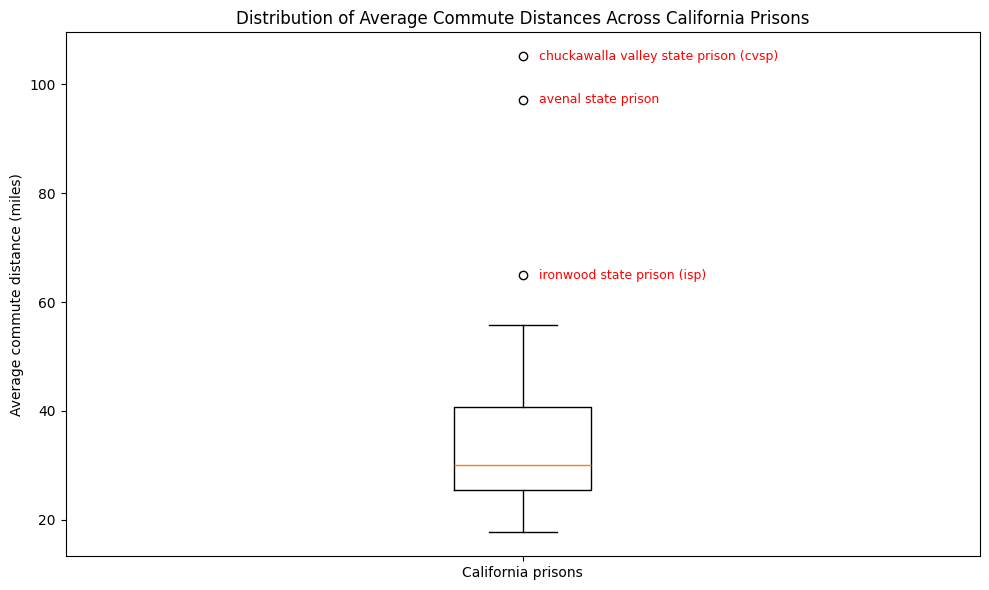

In [125]:
#Distribution of the Weighted Average commuting distances
import matplotlib.pyplot as plt

# Calculate the outlier threshold using the IQR rule
data = results['mean_miles'].dropna()

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

# Identify high outliers
outliers = results[results['mean_miles'] > upper_bound].sort_values(
    'mean_miles', ascending=False
).head(3)

# Draw the boxplot
fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(data, vert=True)

# Label the three highest outliers
for prison, row in outliers.iterrows():
    ax.annotate(
        prison,
        xy=(1, row['mean_miles']),
        xytext=(12, 0),
        textcoords='offset points',
        color='red',
        fontsize=9,
        va='center'
    )

ax.set_ylabel('Weighted Average commute distance (miles)')
ax.set_title('Distribution of Average Commute Distances Across California Prisons')
ax.set_xticks([1])
ax.set_xticklabels(['California prisons'])

plt.tight_layout()
plt.show()

In [126]:
#Descriptive statistics of the weighted average commuting distances for California prisons:

print(results['mean_miles'].describe())

count     30.000000
mean      36.671467
std       20.614717
min       17.658000
25%       25.518750
50%       30.019500
75%       40.671500
max      105.209000
Name: mean_miles, dtype: float64


## 9. Data Visualisations

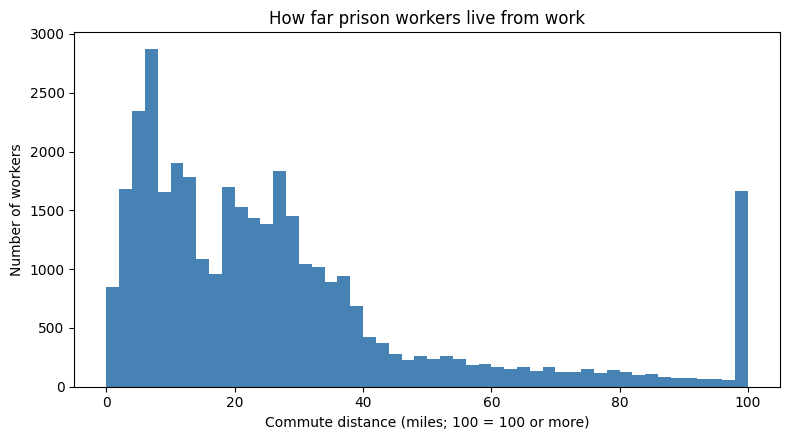

In [127]:
# Distribution of commute distances (weighted by number of jobs), excluding mixed sites
d = pw_d[~pw_d['mixed_site']]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(d['miles'].clip(upper=100), bins=50, weights=d['S000'], color='steelblue')
ax.set_xlabel('Commute distance (miles; 100 = 100 or more)')
ax.set_ylabel('Number of workers')
ax.set_title('How far prison workers live from work')
plt.tight_layout(); plt.show()

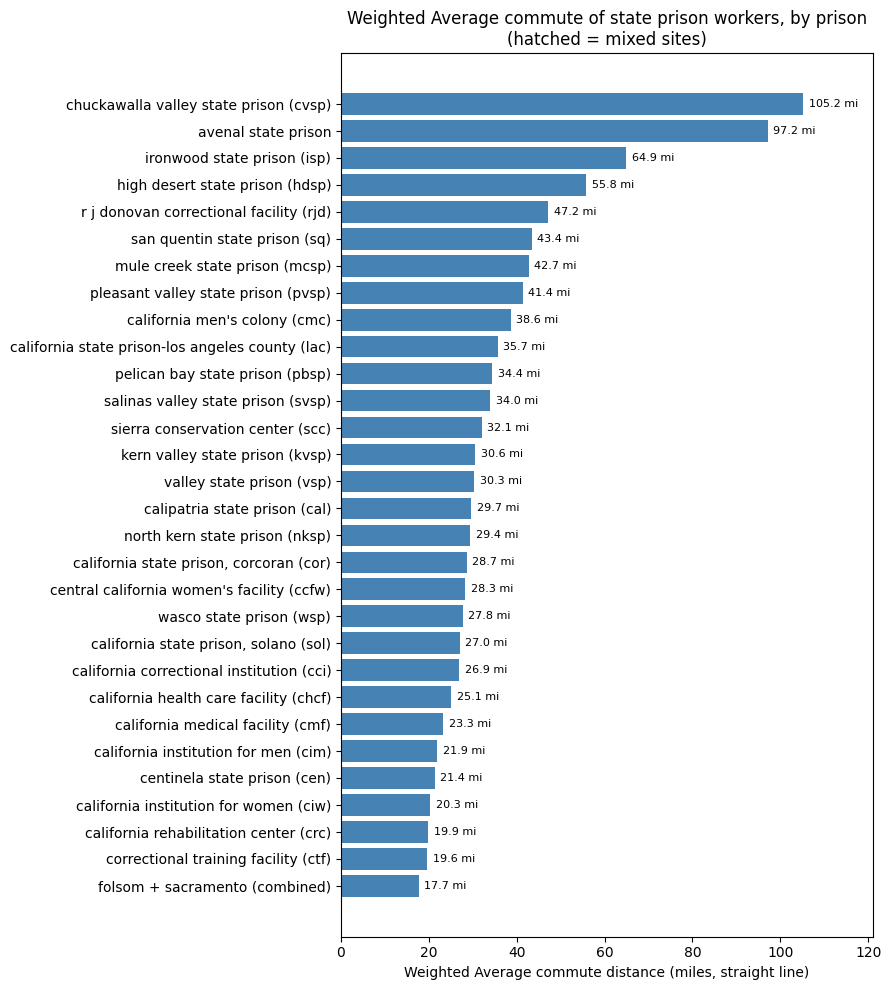

In [150]:
# Average commute by prison (hatched bars = mixed sites, less reliable)
r = results.sort_values('mean_miles')
fig, ax = plt.subplots(figsize=(9, 10))
bars = ax.barh(r.index, r['mean_miles'], color='steelblue')
for bar, mixed in zip(bars, r['mixed_site']):
    if mixed:
        bar.set_facecolor('lightgray'); bar.set_hatch('//')
ax.set_xlabel('Weighted Average commute distance (miles, straight line)')
ax.set_title('Weighted Average commute of state prison workers, by prison\n(hatched = mixed sites)')

# Add average commute distance labels to the end of each bar
ax.bar_label(bars, fmt='%.1f mi', padding=4, fontsize=8)

# Add some space on the right for the labels
ax.set_xlim(0, r['mean_miles'].max() * 1.15)
plt.tight_layout()
plt.savefig('my_graph.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

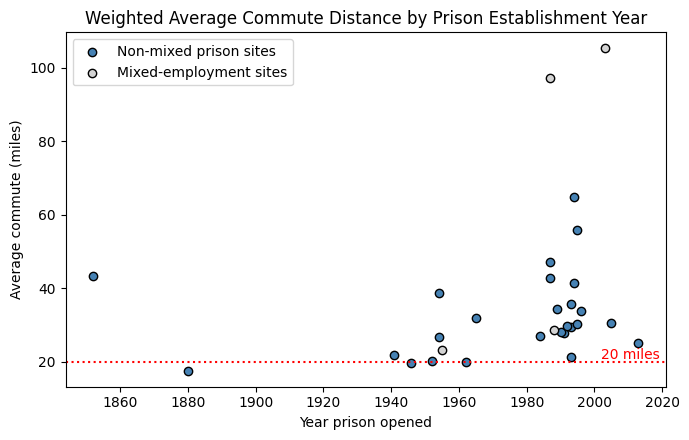

Correlation (non-mixed sites): 0.19


In [140]:
# Prison age vs average commute
r = results.dropna(subset=['establishment_year'])
fig, ax = plt.subplots(figsize=(7, 4.5))

# Blue = non-mixed sites; gray = mixed sites
ax.scatter(
    r.loc[~r['mixed_site'], 'establishment_year'],
    r.loc[~r['mixed_site'], 'mean_miles'],
    color='steelblue',
    edgecolor='k',
    label='Non-mixed prison sites'
)

ax.scatter(
    r.loc[r['mixed_site'], 'establishment_year'],
    r.loc[r['mixed_site'], 'mean_miles'],
    color='lightgray',
    edgecolor='k',
    label='Mixed-employment sites'
)

# Add red dotted reference line at 20 miles
ax.axhline(y=20, color='red', linestyle=':', linewidth=1.5)
ax.text(
    0.99, 20, '20 miles',
    color='red',
    ha='right',
    va='bottom',
    transform=ax.get_yaxis_transform()
)

ax.set_xlabel('Year prison opened')
ax.set_ylabel('Average commute (miles)')
ax.set_title('Weighted Average Commute Distance by Prison Establishment Year')

# Display legend explaining the colors
ax.legend()

plt.tight_layout()
plt.savefig('establishment year.png', dpi=300, bbox_inches='tight')
plt.show()

print('Correlation (non-mixed sites):',
      round(r.loc[~r['mixed_site'],
                  ['establishment_year', 'mean_miles']].corr().iloc[0, 1], 2))

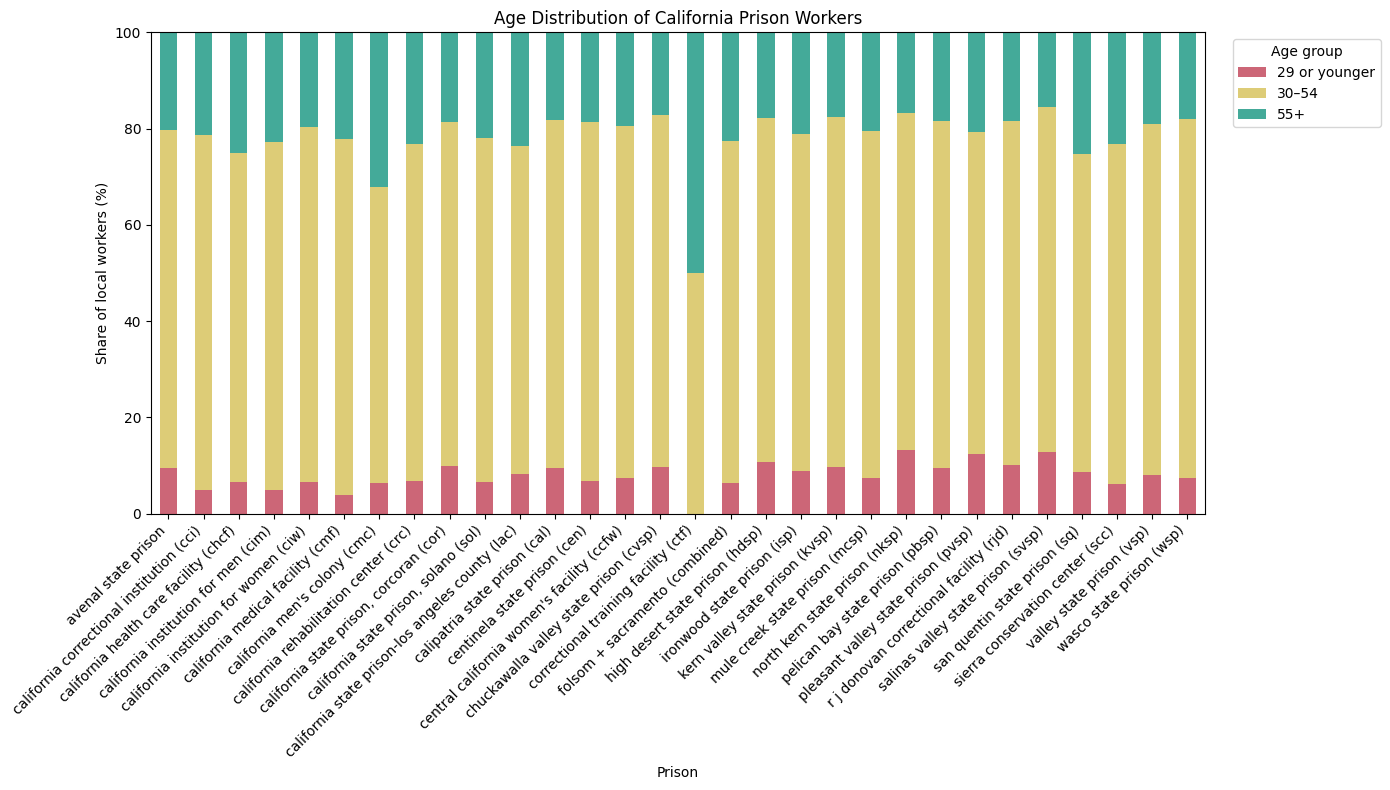

In [147]:
import matplotlib.pyplot as plt
import pandas as pd

# Define local workers: within 20 miles
local = pw_d[pw_d['miles'] <= 20]

# Local workers by age group and prison
local_age = local.groupby('prison')[['SA01', 'SA02', 'SA03']].sum()

# Create plotting dataframe
plot_data = local_age.rename(columns={
    'SA01': '29 or younger',
    'SA02': '30–54',
    'SA03': '55+'
}).fillna(0)

# Convert to percentage of local workers at each prison
plot_pct = plot_data.div(plot_data.sum(axis=1), axis=0) * 100

# Color-blind-friendly colors
colors = [
    '#CC6677',  # Soft Rose Red  — 29 or younger
    '#DDCC77',  # Muted Sand Gold — 30–54
    '#44AA99'   # Soft Teal      — 55+
]

# Plot stacked bars showing local workers' age distribution
ax = plot_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 8),
    color=colors
)

ax.set_ylabel('Share of local workers (%)')
ax.set_xlabel('Prison')
ax.set_title(
    'Age Distribution of California Prison Workers'
)

ax.legend(
    title='Age group',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

ax.set_ylim(0, 100)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('age.png', dpi=300, bbox_inches='tight')
plt.show()

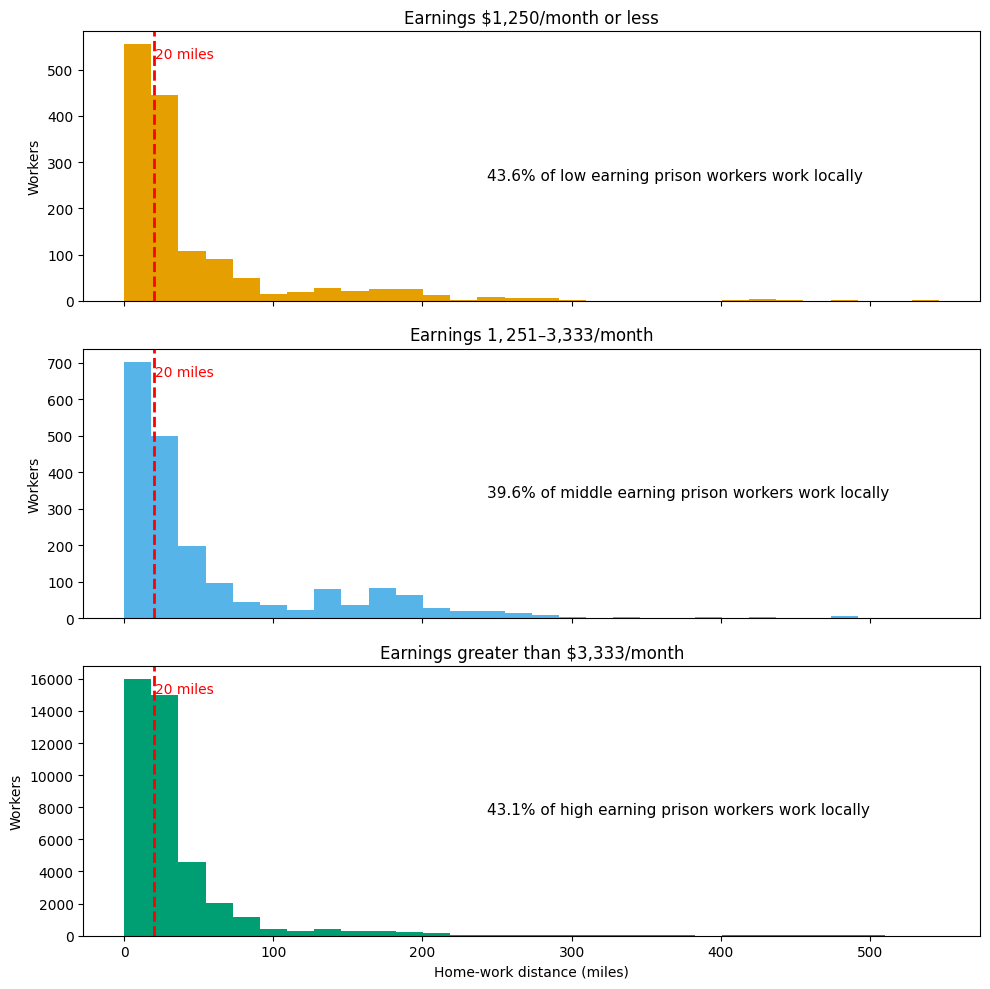

In [131]:
# Calculate the share of each income group living within 20 miles

low_under_20 = (
    pw_d.loc[pw_d['miles'] < 20, 'SE01'].sum()
    / pw_d['SE01'].sum()
)

middle_under_20 = (
    pw_d.loc[pw_d['miles'] < 20, 'SE02'].sum()
    / pw_d['SE02'].sum()
)

high_under_20 = (
    pw_d.loc[pw_d['miles'] < 20, 'SE03'].sum()
    / pw_d['SE03'].sum()
)


# Create three separate histograms showing home-work distance by income group

fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 10),
    sharex=True
)


# Lower-income workers: $1,250/month or less

axes[0].hist(
    pw_d['miles'],
    bins=30,
    weights=pw_d['SE01'],
    color='#E69F00'
)

# Add a red dashed line showing the 20-mile threshold
axes[0].axvline(
    20,
    color='red',
    linestyle='--',
    linewidth=2
)

# Label the 20-mile threshold
axes[0].text(
    20.5,
    axes[0].get_ylim()[1] * 0.90,
    '20 miles',
    color='red',
    fontsize=10
)

# Display the percentage of low-income workers living within 20 miles
axes[0].text(
    0.45,
    0.45,
    f'{low_under_20:.1%} of low earning prison workers work locally',
    transform=axes[0].transAxes,
    fontsize=11
)

axes[0].set_title('Earnings $1,250/month or less')
axes[0].set_ylabel('Workers')


# Middle-income workers: $1,251–$3,333/month

axes[1].hist(
    pw_d['miles'],
    bins=30,
    weights=pw_d['SE02'],
    color='#56B4E9'
)

# Add a red dashed line showing the 20-mile threshold
axes[1].axvline(
    20,
    color='red',
    linestyle='--',
    linewidth=2
)

# Label the 20-mile threshold
axes[1].text(
    20.5,
    axes[1].get_ylim()[1] * 0.90,
    '20 miles',
    color='red',
    fontsize=10
)

# Display the percentage of middle-income workers living within 20 miles
axes[1].text(
    0.45,
    0.45,
    f'{middle_under_20:.1%} of middle earning prison workers work locally',
    transform=axes[1].transAxes,
    fontsize=11
)

axes[1].set_title('Earnings $1,251–$3,333/month')
axes[1].set_ylabel('Workers')


# High-income workers: more than $3,333/month

axes[2].hist(
    pw_d['miles'],
    bins=30,
    weights=pw_d['SE03'],
    color='#009E73'
)

# Add a red dashed line showing the 20-mile threshold
axes[2].axvline(
    20,
    color='red',
    linestyle='--',
    linewidth=2
)

# Label the 20-mile threshold
axes[2].text(
    20.5,
    axes[2].get_ylim()[1] * 0.90,
    '20 miles',
    color='red',
    fontsize=10
)

# Display the percentage of high-income workers living within 20 miles
axes[2].text(
    0.45,
    0.45,
    f'{high_under_20:.1%} of high earning prison workers work locally',
    transform=axes[2].transAxes,
    fontsize=11
)

axes[2].set_title('Earnings greater than $3,333/month')
axes[2].set_ylabel('Workers')
axes[2].set_xlabel('Home-work distance (miles)')


# Display the final figure

plt.tight_layout()
plt.show()

## 10. Save results

In [132]:
results.to_csv(f'{DATA_DIR}/prison_commute_results.csv')
prison_workers.to_csv(f'{DATA_DIR}/prison_workers_lodes.csv', index=False)
print('Saved to', DATA_DIR)

Saved to /content/drive/MyDrive/Python CS/Final/Datasets/


## Limitations to state in the write-up
- **LODES counts jobs, not only prison staff.** Contractors and other employers in the same blocks are included.
- **Block centres, not addresses.** Rural blocks are large, so short distances are approximate.
- **Out-of-state homes have no distance** and are left out of the averages (share printed in section 7).
- **Folsom and New Folsom are combined** because they share a census block.
- **CMF's jobs are mostly health care** (2,214 of 2,227 in its block) and may include another health employer nearby. CMF is flagged as a mixed site.
- **Mixed sites are flagged** (e.g. Pleasant Valley shares its block with a state hospital). Results are shown with and without them.
- **Some prison polygons missed their jobs**; five were fixed by adding nearby blocks within 1 km.
- **Straight-line distance**, not driving distance.